In [1]:
%load_ext autoreload 
%autoreload 2 

# Ranks

Plotting how ranks relate to a modeling and parameter choices.

## 0. Set Up

In [20]:
# Imports

from pathlib import Path
from itertools import cycle

import matplotlib.pyplot as plt

from network_pluralism.access.resolved import to_level
from network_pluralism.access.utils.df import return_top_n


In [21]:
# Matplotlib Config


def set_rcParams(**kwargs):
    params = {
        "pdf.fonttype": 42,
        "text.usetex": True,
        "font.family": "serif",
        "text.latex.preamble": r"\usepackage{amssymb}\usepackage{amsmath}",
        "font.size": 16,
        "legend.fontsize": 14,
        "legend.title_fontsize": 16,
        "axes.labelsize": 18,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "axes.spines.right": False,
        "axes.spines.top": False,
        "legend.columnspacing": 1.0,
        "legend.frameon": False,
        "lines.linewidth": 3,
    }
    for param in kwargs:
        if param in plt.rcParams.keys():
            params[param] = kwargs[param]
    for k, v in params.items():
        plt.rcParams[k] = v


set_rcParams()

In [22]:
EXPORT_PATH = Path('../../figures_and_results/ranks')
EXPORT_PATH.mkdir(exist_ok=True)

# 2. Computiations

### a) Growing Minimum Reference Count

In [5]:
# Small helper func
def binary_matrix_at_least_x_references(x=1, d=2, s=1):
    matrix, rows_mapping, col_mapping = to_level(d,s)

    matrix.data = (matrix.data > x).astype(matrix.data.dtype)
    matrix.eliminate_zeros()
    return matrix

In [6]:
matrix, rows_mapping, col_mapping = to_level(d=2, s=1)

pool_of_top_cited_norms = {}
full_dfs = {}
norms_list = []
for i in range(0, 10):  # 10):
    matirx_at_least_x_references = binary_matrix_at_least_x_references(i)
    df = return_top_n(
        matirx_at_least_x_references,
        rows_mapping,
        col_mapping,
        axis=0,
        top_n=15,
    )
    df_full = return_top_n(
        matirx_at_least_x_references,
        rows_mapping,
        col_mapping,
        axis=0,
        top_n=0,
    )
    full_dfs[i] = df_full
    df["rank"] = df["count"].rank(method="dense", ascending=False).astype(int)
    pool_of_top_cited_norms[i] = df.to_dict()
    norms_list.extend(list(df.index))
    print(i)

Out Matrix of shape (74214, 93645)
Out Matrix of shape (74214, 93645)
0
Out Matrix of shape (74214, 93645)
1
Out Matrix of shape (74214, 93645)
2
Out Matrix of shape (74214, 93645)
3
Out Matrix of shape (74214, 93645)
4
Out Matrix of shape (74214, 93645)
5
Out Matrix of shape (74214, 93645)
6
Out Matrix of shape (74214, 93645)
7
Out Matrix of shape (74214, 93645)
8
Out Matrix of shape (74214, 93645)
9


In [7]:
data_for_viz = []
for norm in set(norms_list):
    min_ref_list = []
    rank_list = []
    for k, data in pool_of_top_cited_norms.items():
        if norm in list(data["rank"]):
            min_ref_list.append(k)
            rank_list.append(data["rank"][norm])
    data_for_viz.append({"Name": [norm for i in range(len(min_ref_list))], "min_ref": min_ref_list, "rank": rank_list})
data_for_viz

[{'Name': ['gg_20', 'gg_20', 'gg_20', 'gg_20'],
  'min_ref': [0, 1, 2, 3],
  'rank': [15, 14, 10, 12]},
 {'Name': ['zpo_574'], 'min_ref': [1], 'rank': [10]},
 {'Name': ['bgb_823', 'bgb_823', 'bgb_823', 'bgb_823'],
  'min_ref': [2, 3, 4, 5],
  'rank': [8, 6, 6, 10]},
 {'Name': ['gg_19',
   'gg_19',
   'gg_19',
   'gg_19',
   'gg_19',
   'gg_19',
   'gg_19',
   'gg_19'],
  'min_ref': [2, 3, 4, 5, 6, 7, 8, 9],
  'rank': [11, 11, 11, 8, 9, 8, 8, 11]},
 {'Name': ['estg_20', 'estg_20', 'estg_20', 'estg_20'],
  'min_ref': [6, 7, 8, 9],
  'rank': [14, 12, 10, 9]},
 {'Name': ['markeng_8',
   'markeng_8',
   'markeng_8',
   'markeng_8',
   'markeng_8',
   'markeng_8',
   'markeng_8',
   'markeng_8',
   'markeng_8',
   'markeng_8'],
  'min_ref': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
  'rank': [14, 1, 1, 1, 1, 1, 1, 1, 1, 1]},
 {'Name': ['gg_33', 'gg_33', 'gg_33', 'gg_33', 'gg_33', 'gg_33', 'gg_33'],
  'min_ref': [3, 4, 5, 6, 7, 8, 9],
  'rank': [15, 12, 7, 6, 6, 4, 5]},
 {'Name': ['gg_14', 'gg_14', 'gg

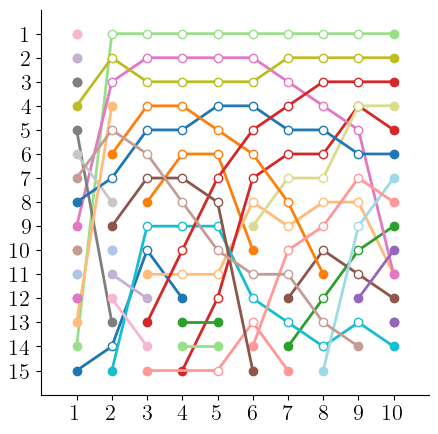

In [23]:
fig, ax = plt.subplots(figsize=(5, 5))

color_cycle = plt.get_cmap('tab20').__dict__['colors']

colors = cycle(color_cycle)

for element in data_for_viz:
    x = [e + 1 for e in element["min_ref"]]
    y = element["rank"]

    color = next(colors)

    ax.plot(x, y, "-", color=color, linewidth=2)  # just the line

    ax.plot(
        x[1:-1],
        y[1:-1],
        "o",
        markerfacecolor="white",
        markeredgecolor=color,
    )

    ax.plot(
        [x[0], x[-1]],
        [y[0], y[-1]],
        "o",
        markerfacecolor=color,
        markeredgecolor=color,
    )

# ax.set_ylabel("Rank")
ax.set_ylim(16, 0)
ax.set_yticks(list(range(1, 16)))
ax.set_yticklabels([str(i) for i in range(1, 16)])

ax.tick_params(axis="both", labelsize=16)

# ax.set_ylabel("Rank")
ax.set_xlim(0, 11)
ax.set_xticks(list(range(1, 11)))
ax.set_xticklabels([str(i) for i in range(1, 11)])

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.yaxis.set_ticks_position("left")
ax.xaxis.set_ticks_position("bottom")
ax.tick_params(top=False, right=False)

# ax.set_xlabel("Minimum references per decision")
plt.savefig(EXPORT_PATH / "rank_over_time.pdf", dpi=600, transparent=True)

### b) Pairwise Comparisons

In [9]:
n = 15

In [10]:
def get_for_x(array, x):
    for el in array:
        if  x in el["Name"] :
            return el

In [11]:
# Return top n cited based on references
top_n_cited_norms_df = return_top_n(matrix, rows_mapping, col_mapping, axis=0, top_n=n)
top_n_cited_norms = list(top_n_cited_norms_df.index)
top_n_cited_norms_dict = {n: i for i, n in enumerate(top_n_cited_norms)}
top_n_cited_norms_dict

{'markeng_8': 0,
 'gg_3': 1,
 'vwgo_132': 2,
 'gg_2': 3,
 'gg_103': 4,
 'fgo_115': 5,
 'gg_20': 6,
 'bgb_307': 7,
 'zpo_563': 8,
 'stpo_349': 9,
 'gg_19': 10,
 'vwgo_154': 11,
 'gg_12': 12,
 'sgg_160': 13,
 'fgo_126': 14}

#### i) Reference Count vs. Decision Count (min. 1)

In [12]:
pairwise_comparison_1 = []
for norm in set(list(pool_of_top_cited_norms[0]["rank"].keys()) + top_n_cited_norms):
    item = {"Name": [], "rank": [], "min_ref": []}
    
    if norm in top_n_cited_norms_dict:
        item["Name"].append(norm)
        item["rank"].append(top_n_cited_norms_dict[norm]+1)
        item["min_ref"].append(0)
        
    if norm in pool_of_top_cited_norms[0]['rank']:
        item["Name"].append(norm)
        item["rank"].append(pool_of_top_cited_norms[0]['rank'][norm])
        item["min_ref"].append(5)
    pairwise_comparison_1.append(item)
pairwise_comparison_1

[{'Name': ['gg_20', 'gg_20'], 'rank': [7, 15], 'min_ref': [0, 5]},
 {'Name': ['gg_19'], 'rank': [11], 'min_ref': [0]},
 {'Name': ['markeng_8', 'markeng_8'], 'rank': [1, 14], 'min_ref': [0, 5]},
 {'Name': ['zpo_97'], 'rank': [2], 'min_ref': [5]},
 {'Name': ['fgo_135'], 'rank': [10], 'min_ref': [5]},
 {'Name': ['vwgo_132', 'vwgo_132'], 'rank': [3, 9], 'min_ref': [0, 5]},
 {'Name': ['vwgo_154', 'vwgo_154'], 'rank': [12, 1], 'min_ref': [0, 5]},
 {'Name': ['stpo_349', 'stpo_349'], 'rank': [10, 5], 'min_ref': [0, 5]},
 {'Name': ['zpo_563', 'zpo_563'], 'rank': [9, 6], 'min_ref': [0, 5]},
 {'Name': ['gg_3', 'gg_3'], 'rank': [2, 4], 'min_ref': [0, 5]},
 {'Name': ['gg_12'], 'rank': [13], 'min_ref': [0]},
 {'Name': ['gg_2', 'gg_2'], 'rank': [4, 8], 'min_ref': [0, 5]},
 {'Name': ['gkg_2004_52'], 'rank': [11], 'min_ref': [5]},
 {'Name': ['fgo_115'], 'rank': [6], 'min_ref': [0]},
 {'Name': ['gkg_2004_47'], 'rank': [13], 'min_ref': [5]},
 {'Name': ['bgb_307'], 'rank': [8], 'min_ref': [0]},
 {'Name': 

In [13]:
pairwise_comparison_1_ordered = []
for x in top_n_cited_norms:
    pairwise_comparison_1_ordered.append(get_for_x(pairwise_comparison_1, x))

# Add remaining
for x in list(
    set([el["Name"][0] for el in pairwise_comparison_1]) - set(top_n_cited_norms)
):
    pairwise_comparison_1_ordered.append(get_for_x(pairwise_comparison_1, x))



In [14]:
greyed_1 = list(
    set([el["Name"][0] for el in pairwise_comparison_1]) - set(top_n_cited_norms)
)


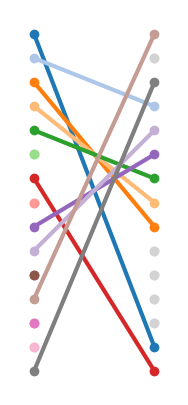

In [15]:
fig, ax = plt.subplots(figsize=(3, 5))

color_cycle = plt.get_cmap("tab20").__dict__["colors"]
colors = cycle(color_cycle)
ax.set_aspect("equal")
for element in pairwise_comparison_1_ordered:
    element_name = element["Name"][0]
    x = [e + 1 for e in element["min_ref"]]
    y = element["rank"]

    color = next(colors) if element_name not in greyed_1 else "lightgrey"

    ax.plot(x, y, "-", color=color)  # just the line
    ax.plot(
        [x[0], x[-1]],
        [y[0], y[-1]],
        "o",
        markerfacecolor=color,
        markeredgecolor=color,
    )
    ax.set_ylim(16, 0)
    ax.set_xlim(0, 7)
    ax.set_axis_off()

plt.savefig(EXPORT_PATH / "pairwise_comparison_1.pdf", dpi=600, transparent=True)

#### iI) Reference Count vs. Decision Count (min. 5)

In [16]:
pairwise_comparison_2 = []
for norm in set(list(pool_of_top_cited_norms[4]["rank"].keys()) + top_n_cited_norms):
    item = {"Name": [], "rank": [], "min_ref": []}
    
    if norm in top_n_cited_norms_dict:
        item["Name"].append(norm)
        item["rank"].append(top_n_cited_norms_dict[norm]+1)
        item["min_ref"].append(0)
        
    if norm in pool_of_top_cited_norms[4]['rank']:
        item["Name"].append(norm)
        item["rank"].append(pool_of_top_cited_norms[4]['rank'][norm])
        item["min_ref"].append(5)
    pairwise_comparison_2.append(item)
pairwise_comparison_2

[{'Name': ['gg_20'], 'rank': [7], 'min_ref': [0]},
 {'Name': ['bgb_823'], 'rank': [6], 'min_ref': [5]},
 {'Name': ['gg_19', 'gg_19'], 'rank': [11, 11], 'min_ref': [0, 5]},
 {'Name': ['markeng_8', 'markeng_8'], 'rank': [1, 1], 'min_ref': [0, 5]},
 {'Name': ['gg_33'], 'rank': [12], 'min_ref': [5]},
 {'Name': ['gg_14'], 'rank': [15], 'min_ref': [5]},
 {'Name': ['vwgo_132', 'vwgo_132'], 'rank': [3, 2], 'min_ref': [0, 5]},
 {'Name': ['vwgo_154'], 'rank': [12], 'min_ref': [0]},
 {'Name': ['zpo_563'], 'rank': [9], 'min_ref': [0]},
 {'Name': ['stpo_349'], 'rank': [10], 'min_ref': [0]},
 {'Name': ['gg_3', 'gg_3'], 'rank': [2, 3], 'min_ref': [0, 5]},
 {'Name': ['gg_12', 'gg_12'], 'rank': [13, 9], 'min_ref': [0, 5]},
 {'Name': ['gg_2', 'gg_2'], 'rank': [4, 4], 'min_ref': [0, 5]},
 {'Name': ['fgo_115', 'fgo_115'], 'rank': [6, 5], 'min_ref': [0, 5]},
 {'Name': ['eg-fgv_2011_27'], 'rank': [13], 'min_ref': [5]},
 {'Name': ['eg-fgv_2011_6'], 'rank': [14], 'min_ref': [5]},
 {'Name': ['bgb_307', 'bgb_30

In [17]:
pairwise_comparison_2_ordered = []
for x in top_n_cited_norms:
    pairwise_comparison_2_ordered.append(get_for_x(pairwise_comparison_2, x))
# Add remaining
for x in list(
    set([el["Name"][0] for el in pairwise_comparison_2]) - set(top_n_cited_norms)
):
    pairwise_comparison_2_ordered.append(get_for_x(pairwise_comparison_2, x))

In [18]:
greyed_2 = list(set([el['Name'][0] for el in pairwise_comparison_2]) - set(top_n_cited_norms))

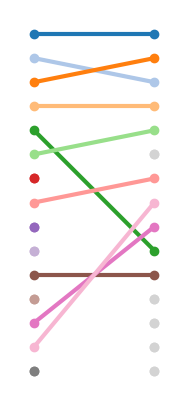

In [19]:
fig, ax = plt.subplots(figsize=(3, 5))

color_cycle = plt.get_cmap("tab20").__dict__["colors"]
colors = cycle(color_cycle)
ax.set_aspect("equal")
for element in pairwise_comparison_2_ordered:
    element_name = element["Name"][0]
    x = [e + 1 for e in element["min_ref"]]
    y = element["rank"]

    color = next(colors) if element_name not in greyed_2 else "lightgrey"
    ax.plot(x, y, "-", color=color)  # just the line

    ax.plot(
        [x[0], x[-1]],
        [y[0], y[-1]],
        "o",
        markerfacecolor=color,
        markeredgecolor=color,
    )
    ax.set_ylim(16, 0)

    ax.set_xlim(0, 7)
    ax.set_axis_off()

plt.savefig(EXPORT_PATH / "pairwise_comparison_2.pdf", dpi=600, transparent=True)